In [3]:
from langgraph.graph import StateGraph
from typing import TypedDict, Self
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver
load_dotenv()

True

In [7]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
)
res = llm.invoke("Give me a joke")

In [14]:
res.content[-1]["text"]

"Why don't scientists trust atoms?\n\nBecause they make up everything!"

In [5]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [ ]:
# Task1 
def generate_joke(state: JokeState) -> Self:
    prompt = f"Generate a joke from the topic: {state['topic']}."
    joke_response = llm.invoke(prompt).content[-1]["text"]
    return {"joke": joke_response}

def generate_explanation(state: JokeState) -> Self:
    prompt = f"Give the explanation of the joke: {state['joke']}"
    explanation_response = llm.invoke(prompt).content[-1]["text"]
    return {"explanation": explanation_response}

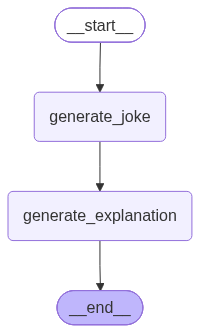

In [28]:
graph = StateGraph(state_schema = JokeState)

# Add nodes
graph.add_node(node = "generate_joke", action = generate_joke)
graph.add_node(node = "generate_explanation", action = generate_explanation)

# Add edges
graph.set_entry_point(key = "generate_joke")
graph.add_edge("generate_joke", "generate_explanation")
graph.set_finish_point(key = "generate_explanation")

# Create Checkpointer
memory = InMemorySaver()

# Compilation
workflow = graph.compile(checkpointer = memory) # Here we specify that we want to save the intermediate + final state values of the graph in the RAM(Memory)
workflow

In [51]:
# Invocation
initial_state = {"topic": "House"}
config2 = {"configurable": {"thread_id": "0"}}
res = workflow.invoke(initial_state, config = config2)

In [52]:
res

{'topic': 'House',
 'joke': 'Why are houses so good at telling jokes?\n\nBecause they have **great stories!**',
 'explanation': 'The explanation of this joke relies on a **pun** (a play on words) involving the word **"stories."**\n\nHere is the breakdown:\n\n1.  **In architecture:** A "story" is the technical term for a floor or a level of a building (e.g., a "two-story house").\n2.  **In literature/comedy:** A "story" is a narrative or an anecdote—the essential component of a joke.\n\nThe joke uses the word "stories" to mean two different things at once: the house has multiple levels (structural stories) and the house has funny things to say (narrative stories).'}

In [53]:
# Returns the final state of the workflow for the given thread_id
workflow.get_state(config = config2) 

StateSnapshot(values={'topic': 'House', 'joke': 'Why are houses so good at telling jokes?\n\nBecause they have **great stories!**', 'explanation': 'The explanation of this joke relies on a **pun** (a play on words) involving the word **"stories."**\n\nHere is the breakdown:\n\n1.  **In architecture:** A "story" is the technical term for a floor or a level of a building (e.g., a "two-story house").\n2.  **In literature/comedy:** A "story" is a narrative or an anecdote—the essential component of a joke.\n\nThe joke uses the word "stories" to mean two different things at once: the house has multiple levels (structural stories) and the house has funny things to say (narrative stories).'}, next=(), config={'configurable': {'thread_id': '0', 'checkpoint_ns': '', 'checkpoint_id': '1f1a5dc4-f772-6c9a-8006-00d6dd30d03f'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-09-01T08:08:26.979445+00:00', parent_config={'configurable': {'thread_id': '0', 'checkpoint_ns': '', '

In [54]:
# Returns the intermediate states of the workflow for the given thread_id
list(workflow.get_state_history(config = config2))

[StateSnapshot(values={'topic': 'House', 'joke': 'Why are houses so good at telling jokes?\n\nBecause they have **great stories!**', 'explanation': 'The explanation of this joke relies on a **pun** (a play on words) involving the word **"stories."**\n\nHere is the breakdown:\n\n1.  **In architecture:** A "story" is the technical term for a floor or a level of a building (e.g., a "two-story house").\n2.  **In literature/comedy:** A "story" is a narrative or an anecdote—the essential component of a joke.\n\nThe joke uses the word "stories" to mean two different things at once: the house has multiple levels (structural stories) and the house has funny things to say (narrative stories).'}, next=(), config={'configurable': {'thread_id': '0', 'checkpoint_ns': '', 'checkpoint_id': '1f1a5dc4-f772-6c9a-8006-00d6dd30d03f'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-09-01T08:08:26.979445+00:00', parent_config={'configurable': {'thread_id': '0', 'checkpoint_ns': '', 